# Bipartite and hypergraph connectivity vs. protein sequence features

Relates protein connectivity in the condensate network to disorder (IUPred) and sequence-composition features.

**Connectivity measures**
- *Projection degree*: degree of the protein in the one-mode projection of the protein-condensate bipartite graph.
- *Hyperdegree*: number of condensates a protein belongs to (its degree in the bipartite graph).

**Analysis scenarios** (all correlations are computed for each one)
1. **All proteins**.
2. **Excluding degree-1 proteins**: proteins that belong to a single condensate (hyperdegree = 1) are removed from the correlation sample. Degrees are those of the full network.
3. **Excluding the largest condensate**: the condensate with the most proteins is removed from the data, the bipartite graph and its projection are rebuilt, and both degrees are recomputed.

**Multiple-testing correction**: within each scenario, all feature x target x method tests form one family and p-values are adjusted with the method chosen in the configuration cell (Benjamini-Hochberg FDR by default; Holm and Bonferroni are also reported). Significance stars in figures and tables use the adjusted p-values.

## 1. Setup and configuration

In [ ]:
import ast
import json
import re

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import seaborn as sns
from networkx.algorithms import bipartite

from preprocessing import create_hypergraph
from utils import *

In [40]:
# ---- Input files ----
PROTEINS_JSON = "CD-Code Dump 17_12_25/01/proteins.json"
DF_ROLES_CSV = "data/df_with_roles.csv"
FINAL_PROTEINS_CSV = "data/final_proteins.csv"
FINAL_CONDENSATES_CSV = "data/final_condensates.csv"
MAPPING_TSV = "CD-Code Dump 17_12_25/01/protein2cdcode_v2.1.tsv"

# ---- Hypergraph construction ----
MIN_PROTEINS_HYPERGRAPH = 3

# ---- Disorder features ----
DISORDER_THRESHOLDS = (0.50, 0.60, 0.75)

# ---- Sequence-composition residue sets ----
STICKERS = set("YFR")
IDRS = set("SGQN")
REACTIVE = set("YFRSGQN")

# ---- Statistics ----
ALPHA = 0.05
CORRECTION_METHOD = "holm"          # one of: "fdr_bh", "holm", "bonferroni"
FAMILY_COLS = ("Scenario",)           # tests are corrected jointly within each group
METHODS = ("Pearson", "Spearman")
TARGETS = ("Hyperdegree", "Projection Degree")

CORRECTION_LABELS = {
    "fdr_bh": "Benjamini-Hochberg",
    "holm": "Holm",
    "bonferroni": "Bonferroni",
}
P_ADJ_COLUMNS = {
    "fdr_bh": "p_fdr_bh",
    "holm": "p_holm",
    "bonferroni": "p_bonferroni",
}

# ---- Scenario names ----
SCENARIO_ALL = "All proteins"
SCENARIO_NO_DEG1 = "Excluding hyper-degree-1 proteins"
SCENARIO_NO_LARGEST = "Excluding largest condensate"

# ---- Feature names (columns of the protein feature table) ----
IUPRED_FEATURES = (
    ["Mean IUPred Score", "IUPred Score std"]
    + [f"Num. Disordered Regions_{round(t * 100)}" for t in DISORDER_THRESHOLDS]
    + [f"Max Disordered Length_{round(t * 100)}" for t in DISORDER_THRESHOLDS]
)
SEQ_FEATURES = ["Sticker Fraction", "IDR Fraction", "Reactive Fraction"]
ALL_FEATURES = IUPRED_FEATURES + SEQ_FEATURES

# ---- Display labels (insertion order = row order in figures and tables) ----
HEATMAP_LABELS = {
    "Mean IUPred Score": "Mean IUPred",
    "IUPred Score std": "IUPred SD",
    "Num. Disordered Regions_50": "Disordered regions",
    "Max Disordered Length_50": "Max disorder length",
    "Sticker Fraction": "Sticker fraction",
    "IDR Fraction": "IDR fraction",
    "Reactive Fraction": "Reactive fraction",
}
LATEX_LABELS = {
    "Num. Disordered Regions_50": "Num. disordered regions",
    "Max Disordered Length_50": "Max disordered length",
    "Mean IUPred Score": "Mean IUPred Score",
    "IUPred Score std": "IUPred Score std",
    "Sticker Fraction": "Sticker fraction",
    "IDR Fraction": "IDR fraction",
    "Reactive Fraction": "Reactive fraction",
}
TARGET_LABELS = {"Hyperdegree": "Hypergraph", "Projection Degree": "Projection"}

## Data loading

In [45]:
with open(PROTEINS_JSON, "r") as f:
    protein_records = json.load(f)["protein"]

protein_seqs = pd.DataFrame(protein_records)[["uniprot_id", "sequence"]]
print("Missing values in protein table:")
print(protein_seqs.isna().sum())

protein_seqs = protein_seqs.dropna(subset=["sequence"]).drop_duplicates("uniprot_id")

df = pd.read_csv(DF_ROLES_CSV).merge(protein_seqs, on="uniprot_id", how="left")

print(f"\nRows in df: {len(df)}")
print(f"Proteins: {df['uniprot_id'].nunique()}, condensates: {df['condensate_id'].nunique()}")
print(f"Rows without sequence after merge: {df['sequence'].isna().sum()}")

Missing values in protein table:
uniprot_id      0
sequence      100
dtype: int64

Rows in df: 6885
Proteins: 4352, condensates: 109
Rows without sequence after merge: 0


## Bipartite graph and protein projection

In [46]:
edges = df[["uniprot_id", "condensate_id"]].drop_duplicates()

full_degrees, B, protein_projection = compute_degrees(edges)
print(f"Is bipartite: {bipartite.is_bipartite(B)}")
print(f"Proteins: {len(full_degrees)}, condensates: {edges['condensate_id'].nunique()}, edges: {len(edges)}")

Is bipartite: True
Proteins: 4352, condensates: 109, edges: 6885


In [47]:
# Slow on large projections (clustering coefficient); uncomment to run.
# describe_projected_graph(protein_projection)

## Hypergraph degree vs. projection degree

Hyperdegrees here come from the hypergraph built by `create_hypergraph` (condensates with fewer than `MIN_PROTEINS_HYPERGRAPH` proteins are excluded), compared with the projection degree of the full bipartite graph. The two tests form their own family for multiple-testing correction.

In [49]:
final_proteins = pd.read_csv(FINAL_PROTEINS_CSV)
final_condensates = pd.read_csv(FINAL_CONDENSATES_CSV)
mapping = pd.read_csv(MAPPING_TSV, sep="\t", header=0)

H = create_hypergraph(final_proteins, final_condensates, mapping, min_proteins=MIN_PROTEINS_HYPERGRAPH)

# Series keyed by uniprot_id so degrees align with the projection degrees
hypergraph_degrees = pd.Series(
    H.nodes.degree.asnumpy(), index=list(H.nodes), name="Hypergraph Degree"
)
aligned = pd.concat([full_degrees["Projection Degree"], hypergraph_degrees], axis=1).dropna()
print(f"Proteins present in both graphs: {len(aligned)}")
aligned.head()

Proteins present in both graphs: 4352


,Projection Degree,Hypergraph Degree
Q92804,2508,9
O43791,218,2
Q16082,23,2
P14866,2447,5
Q04726,14,1


In [50]:
res = correlate(aligned["Projection Degree"], aligned["Hypergraph Degree"])
degree_consistency = pd.DataFrame([
    {
        "Scenario": "Degree consistency",
        "Method": m,
        "r": res[m][0],
        "p": res[m][1],
        "n": res["n"],
    }
    for m in METHODS
])
degree_consistency = add_adjusted_pvalues(degree_consistency)
degree_consistency

,Scenario,Method,r,p,n,p_fdr_bh,p_holm,p_bonferroni,p_adj,significant
0,Degree consistency,Pearson,0.634463,0.0,4352,0.0,0.0,0.0,0.0,True
1,Degree consistency,Spearman,0.711228,0.0,4352,0.0,0.0,0.0,0.0,True


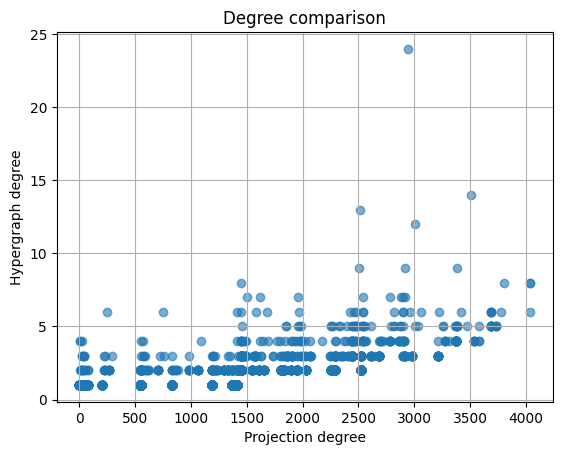

In [51]:
plt.scatter(aligned["Projection Degree"], aligned["Hypergraph Degree"], alpha=0.6)
plt.xlabel("Projection degree")
plt.ylabel("Hypergraph degree")
plt.title("Degree comparison")
plt.grid(True)
plt.show()

## Protein-level features

One row per protein with IUPred-derived features (mean, standard deviation, longest disordered stretch and number of disordered regions at each threshold) and sequence-composition fractions (sticker, IDR and reactive residues).

In [52]:
protein_table = (
    df.drop_duplicates("uniprot_id")[["uniprot_id", "protein_name", "iupred_score", "sequence"]]
    .reset_index(drop=True)
)
protein_table["iupred_score"] = protein_table["iupred_score"].apply(parse_scores)
scores = protein_table["iupred_score"]

features_df = pd.DataFrame({"uniprot_id": protein_table["uniprot_id"]})
features_df["Mean IUPred Score"] = scores.apply(np.mean)
features_df["IUPred Score std"] = scores.apply(np.std)
for t in DISORDER_THRESHOLDS:
    tag = round(t * 100)
    features_df[f"Num. Disordered Regions_{tag}"] = scores.apply(lambda a, t=t: count_regions(a, threshold=t))
for t in DISORDER_THRESHOLDS:
    tag = round(t * 100)
    features_df[f"Max Disordered Length_{tag}"] = scores.apply(lambda a, t=t: longest_run(a, threshold=t))

features_df["Sticker Fraction"] = protein_table["sequence"].apply(lambda s: residue_fraction(s, STICKERS))
features_df["IDR Fraction"] = protein_table["sequence"].apply(lambda s: residue_fraction(s, IDRS))
features_df["Reactive Fraction"] = protein_table["sequence"].apply(lambda s: residue_fraction(s, REACTIVE))

print(f"features_df shape: {features_df.shape}")
features_df.head()

features_df shape: (4352, 12)


,uniprot_id,Mean IUPred Score,IUPred Score std,Num. Disordered Regions_50,Num. Disordered Regions_60,Num. Disordered Regions_75,Max Disordered Length_50,Max Disordered Length_60,Max Disordered Length_75,Sticker Fraction,IDR Fraction,Reactive Fraction
0,Q92804,0.712272,0.139888,10,19,16,243,242,144,0.207770,0.515203,0.722973
1,O43791,0.175839,0.141045,3,3,0,12,8,0,0.117647,0.203209,0.320856
2,Q16082,0.436673,0.168064,10,7,5,18,11,8,0.164835,0.170330,0.335165
3,P14866,0.456148,0.272267,8,9,9,106,54,32,0.144312,0.293718,0.438031
4,Q04726,0.464775,0.294643,17,12,5,230,176,166,0.090674,0.266839,0.357513


## 7. Analysis scenarios

- **All proteins**: degrees from the full network.
- **Excluding degree-1 proteins**: proteins with hyperdegree 1 are dropped from the sample; degrees are still those of the full network.
- **Excluding largest condensate**: the condensate with the most proteins is removed, the graph and projection are rebuilt and degrees recomputed. Proteins that only belonged to that condensate no longer appear in the network and are dropped.

In [ ]:
def build_analysis_frame(degrees):
    """Join a degree table with the protein feature table (one row per protein)."""
    return degrees.reset_index().merge(features_df, on="uniprot_id", how="left")

# Scenario 1: all proteins
frame_all = build_analysis_frame(full_degrees)

# Scenario 2: drop proteins that belong to a single condensate (hyperdegree == 1)
frame_no_deg1 = frame_all[frame_all["Hyperdegree"] > 1].reset_index(drop=True)

# Scenario 3: drop the largest condensate and recompute the network
condensate_sizes = edges.groupby("condensate_id")["uniprot_id"].nunique()
largest_condensate = condensate_sizes.idxmax()
largest_name = df.loc[df["condensate_id"] == largest_condensate, "condensate_name"].iloc[0]
print(f"Largest condensate: {largest_condensate} ({largest_name}) with {condensate_sizes.max()} proteins")

edges_no_largest = edges[edges["condensate_id"] != largest_condensate]
degrees_no_largest, B_no_largest, projection_no_largest = compute_degrees(edges_no_largest)
frame_no_largest = build_analysis_frame(degrees_no_largest)

scenarios = {
    SCENARIO_ALL: frame_all,
    SCENARIO_NO_DEG1: frame_no_deg1,
    SCENARIO_NO_LARGEST: frame_no_largest,
}

print()
for name, frame in scenarios.items():
    print(f"{name}: {len(frame)} proteins")
print(f"Proteins lost with the largest condensate: {len(frame_all) - len(frame_no_largest)}")

Largest condensate: 91857CE7 (Nucleolus) with 1413 proteins

All proteins: 4352 proteins
Excluding hyper-degree-1 proteins: 1492 proteins
Excluding largest condensate: 3627 proteins
Proteins lost with the largest condensate: 725


## Correlations with multiple-testing correction

Each scenario contains `len(ALL_FEATURES) x len(TARGETS) x len(METHODS)` tests. Raw p-values are kept in `p`; Bonferroni, Holm and Benjamini-Hochberg adjusted values are in `p_bonferroni`, `p_holm` and `p_fdr_bh`. `p_adj` is the method selected by `CORRECTION_METHOD`.

In [54]:
results = pd.concat(
    [correlation_table(frame, ALL_FEATURES, TARGETS, name) for name, frame in scenarios.items()],
    ignore_index=True,
)
results = add_adjusted_pvalues(results)
results

,Scenario,Feature,Target,Method,r,p,n,p_fdr_bh,p_holm,p_bonferroni,p_adj,significant
0,All proteins,Mean IUPred Score,Hyperdegree,Pearson,0.052784,4.947434e-04,4352,8.707484e-04,9.894868e-03,2.176871e-02,9.894868e-03,True
1,All proteins,Mean IUPred Score,Hyperdegree,Spearman,0.036818,1.513934e-02,4352,1.959208e-02,1.796125e-01,6.661308e-01,1.796125e-01,False
2,All proteins,Mean IUPred Score,Projection Degree,Pearson,-0.120086,1.887463e-15,4352,2.076209e-14,7.738597e-14,8.304836e-14,7.738597e-14,True
3,All proteins,Mean IUPred Score,Projection Degree,Spearman,-0.082545,4.946746e-08,4352,1.813807e-07,1.632426e-06,2.176568e-06,1.632426e-06,True
4,All proteins,IUPred Score std,Hyperdegree,Pearson,0.006595,6.635797e-01,4352,7.121343e-01,1.000000e+00,1.000000e+00,1.000000e+00,False
...,...,...,...,...,...,...,...,...,...,...,...,...
127,Excluding largest condensate,IDR Fraction,Projection Degree,Spearman,-0.071356,1.697272e-05,3627,3.111665e-05,3.564271e-04,7.467995e-04,3.564271e-04,True
128,Excluding largest condensate,Reactive Fraction,Hyperdegree,Pearson,0.184109,5.124007e-29,3627,2.254563e-27,2.254563e-27,2.254563e-27,2.254563e-27,True
129,Excluding largest condensate,Reactive Fraction,Hyperdegree,Spearman,0.056894,6.080697e-04,3627,8.918356e-04,9.121045e-03,2.675507e-02,9.121045e-03,True
130,Excluding largest condensate,Reactive Fraction,Projection Degree,Pearson,-0.060218,2.848994e-04,3627,4.322612e-04,4.558391e-03,1.253558e-02,4.558391e-03,True


### Effect of the correction

In [55]:
correction_summary = results.groupby("Scenario", sort=False).agg(
    n_tests=("p", "size"),
    significant_raw=("p", lambda s: int((s < ALPHA).sum())),
    significant_adjusted=("significant", "sum"),
)
correction_summary["significant_adjusted"] = correction_summary["significant_adjusted"].astype(int)
print(f"Adjustment: {CORRECTION_LABELS[CORRECTION_METHOD]}, alpha = {ALPHA}")
correction_summary

Adjustment: Holm, alpha = 0.05


,n_tests,significant_raw,significant_adjusted
Scenario,,,
All proteins,44,35,28
Excluding hyper-degree-1 proteins,44,28,24
Excluding largest condensate,44,36,32


### Scenario comparison (r with stars from adjusted p-values)

In [56]:
def comparison_table(results, method):
    """Features x targets by scenario, showing r and significance stars of the adjusted p."""
    tmp = results[results["Method"] == method].copy()
    tmp["cell"] = [f"{r:.3f}{p_to_stars(p)}" for r, p in zip(tmp["r"], tmp["p_adj"])]
    table = tmp.pivot(index=["Feature", "Target"], columns="Scenario", values="cell")
    row_order = pd.MultiIndex.from_product([ALL_FEATURES, TARGETS], names=["Feature", "Target"])
    return table.reindex(index=row_order, columns=list(scenarios))


comparison_table(results, "Pearson")

Scenario                                     All proteins  \
Feature                    Target                           
Mean IUPred Score          Hyperdegree            0.053**   
                           Projection Degree    -0.120***   
IUPred Score std           Hyperdegree              0.007   
                           Projection Degree    -0.098***   
Num. Disordered Regions_50 Hyperdegree              0.007   
                           Projection Degree      -0.049*   
Num. Disordered Regions_60 Hyperdegree              0.004   
                           Projection Degree    -0.073***   
Num. Disordered Regions_75 Hyperdegree             -0.005   
                           Projection Degree    -0.117***   
Max Disordered Length_50   Hyperdegree              0.039   
                           Projection Degree    -0.097***   
Max Disordered Length_60   Hyperdegree             0.049*   
                           Projection Degree    -0.089***   
Max Disordered Length_75   Hyperdegree              0.039   
                           Projection Degree    -0.079***   
Sticker Fraction           Hyperdegree           0.068***   
                           Projection Degree     0.063***   
IDR Fraction               Hyperdegree           0.122***   
                           Projection Degree    -0.115***   
Reactive Fraction          Hyperdegree           0.149***   
                           Projection Degree     -0.059**   

Scenario                                     Excluding hyper-degree-1 proteins  \
Feature                    Target                                                
Mean IUPred Score          Hyperdegree                                  0.081*   
                           Projection Degree                         -0.251***   
IUPred Score std           Hyperdegree                                  -0.029   
                           Projection Degree                         -0.240***   
Num. Disordered Regions_50 Hyperdegree                                  -0.016   
                           Projection Degree                            -0.073   
Num. Disordered Regions_60 Hyperdegree                                  -0.025   
                           Projection Degree                         -0.113***   
Num. Disordered Regions_75 Hyperdegree                                  -0.024   
                           Projection Degree                         -0.192***   
Max Disordered Length_50   Hyperdegree                                   0.037   
                           Projection Degree                         -0.219***   
Max Disordered Length_60   Hyperdegree                                   0.064   
                           Projection Degree                         -0.203***   
Max Disordered Length_75   Hyperdegree                                   0.048   
                           Projection Degree                         -0.184***   
Sticker Fraction           Hyperdegree                                0.112***   
                           Projection Degree                             0.041   
IDR Fraction               Hyperdegree                                0.226***   
                           Projection Degree                         -0.186***   
Reactive Fraction          Hyperdegree                                0.249***   
                           Projection Degree                         -0.127***   

Scenario                                     Excluding largest condensate  
Feature                    Target                                          
Mean IUPred Score          Hyperdegree                           0.091***  
                           Projection Degree                    -0.137***  
IUPred Score std           Hyperdegree                              0.024  
                           Projection Degree                    -0.102***  
Num. Disordered Regions_50 Hyperdegree                              0.017  
                           Project

In [57]:
comparison_table(results, "Spearman")

Scenario                                     All proteins  \
Feature                    Target                           
Mean IUPred Score          Hyperdegree              0.037   
                           Projection Degree    -0.083***   
IUPred Score std           Hyperdegree              0.018   
                           Projection Degree    -0.071***   
Num. Disordered Regions_50 Hyperdegree             0.050*   
                           Projection Degree    -0.066***   
Num. Disordered Regions_60 Hyperdegree              0.034   
                           Projection Degree    -0.091***   
Num. Disordered Regions_75 Hyperdegree              0.016   
                           Projection Degree    -0.106***   
Max Disordered Length_50   Hyperdegree              0.037   
                           Projection Degree    -0.079***   
Max Disordered Length_60   Hyperdegree              0.037   
                           Projection Degree    -0.074***   
Max Disordered Length_75   Hyperdegree              0.039   
                           Projection Degree    -0.068***   
Sticker Fraction           Hyperdegree              0.020   
                           Projection Degree      0.061**   
IDR Fraction               Hyperdegree              0.006   
                           Projection Degree    -0.125***   
Reactive Fraction          Hyperdegree              0.016   
                           Projection Degree    -0.082***   

Scenario                                     Excluding hyper-degree-1 proteins  \
Feature                    Target                                                
Mean IUPred Score          Hyperdegree                                   0.022   
                           Projection Degree                         -0.257***   
IUPred Score std           Hyperdegree                                  -0.032   
                           Projection Degree                         -0.242***   
Num. Disordered Regions_50 Hyperdegree                                   0.014   
                           Projection Degree                         -0.194***   
Num. Disordered Regions_60 Hyperdegree                                  -0.011   
                           Projection Degree                         -0.255***   
Num. Disordered Regions_75 Hyperdegree                                  -0.019   
                           Projection Degree                         -0.277***   
Max Disordered Length_50   Hyperdegree                                   0.018   
                           Projection Degree                         -0.265***   
Max Disordered Length_60   Hyperdegree                                   0.023   
                           Projection Degree                         -0.259***   
Max Disordered Length_75   Hyperdegree                                   0.011   
                           Projection Degree                         -0.254***   
Sticker Fraction           Hyperdegree                                 0.093**   
                           Projection Degree                             0.060   
IDR Fraction               Hyperdegree                                   0.030   
                           Projection Degree                         -0.224***   
Reactive Fraction          Hyperdegree                                   0.067   
                           Projection Degree                         -0.193***   

Scenario                                     Excluding largest condensate  
Feature                    Target                                          
Mean IUPred Score          Hyperdegree                           0.075***  
                           Projection Degree                    -0.121***  
IUPred Score std           Hyperdegree                              0.041  
                           Projection Degree                    -0.083***  
Num. Disordered Regions_50 Hyperdegree                           0.082***  
                           Project

## Heatmaps

One figure per scenario. Colours show the correlation coefficient; stars show significance of the adjusted p-value.

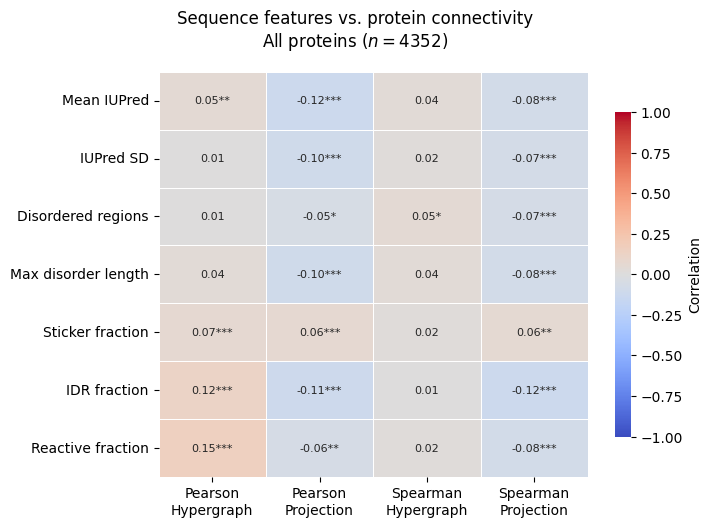

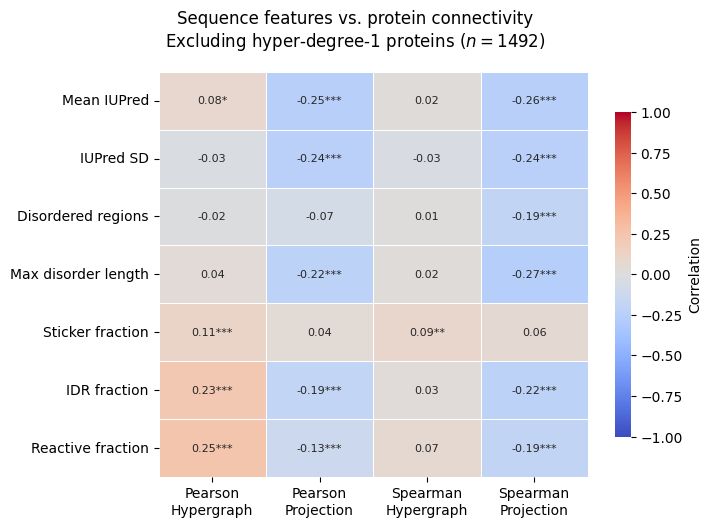

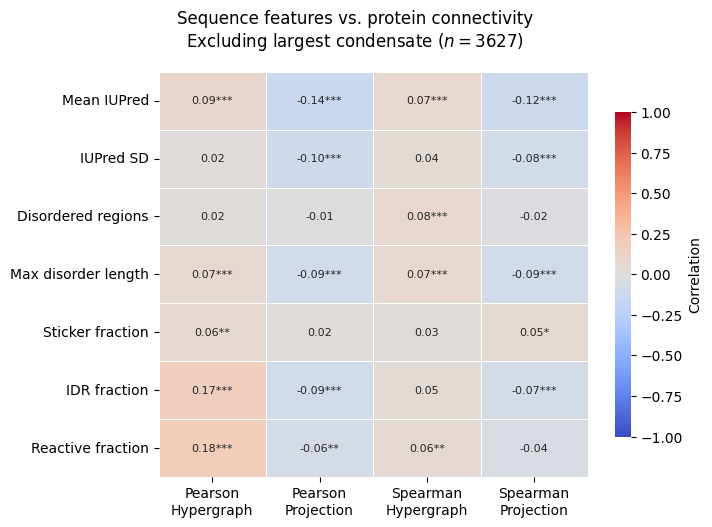

In [58]:
for name in scenarios:
    plot_correlation_heatmap(results, name)

## 10. LaTeX tables

Generated from the results above. Stars use adjusted p-values.

In [59]:
for name in scenarios:
    print(make_latex_table(results, name))
    print()

\begin{table}
\caption{Correlation between sequence-derived features and node connectivity measures (all proteins, $n = 4352$).}
\label{tab:correlations_all_proteins}
\begin{tabular}{lcccc}
\toprule
& Projection Degree & Hyperdegree & Projection Degree & Hyperdegree \\
Feature & (Pearson) & (Pearson) & (Spearman) & (Spearman) \\
\midrule
Num. disordered regions & -0.049* & 0.007 & -0.066*** & 0.050* \\
Max disordered length & -0.097*** & 0.039 & -0.079*** & 0.037 \\
Mean IUPred Score & -0.120*** & 0.053** & -0.083*** & 0.037 \\
IUPred Score std & -0.098*** & 0.007 & -0.071*** & 0.018 \\
Sticker fraction & 0.063*** & 0.068*** & 0.061** & 0.020 \\
IDR fraction & -0.115*** & 0.122*** & -0.125*** & 0.006 \\
Reactive fraction & -0.059** & 0.149*** & -0.082*** & 0.016 \\
\bottomrule
\multicolumn{5}{l}{\footnotesize \textit{Note:} *** $p_{\mathrm{adj}} < 0.001$, ** $p_{\mathrm{adj}} < 0.01$, * $p_{\mathrm{adj}} < 0.05$ (Holm correction).} \\
\end{tabular}
\end{table}

\begin{table}
\caption{C

## Sequence-fraction scatter plots

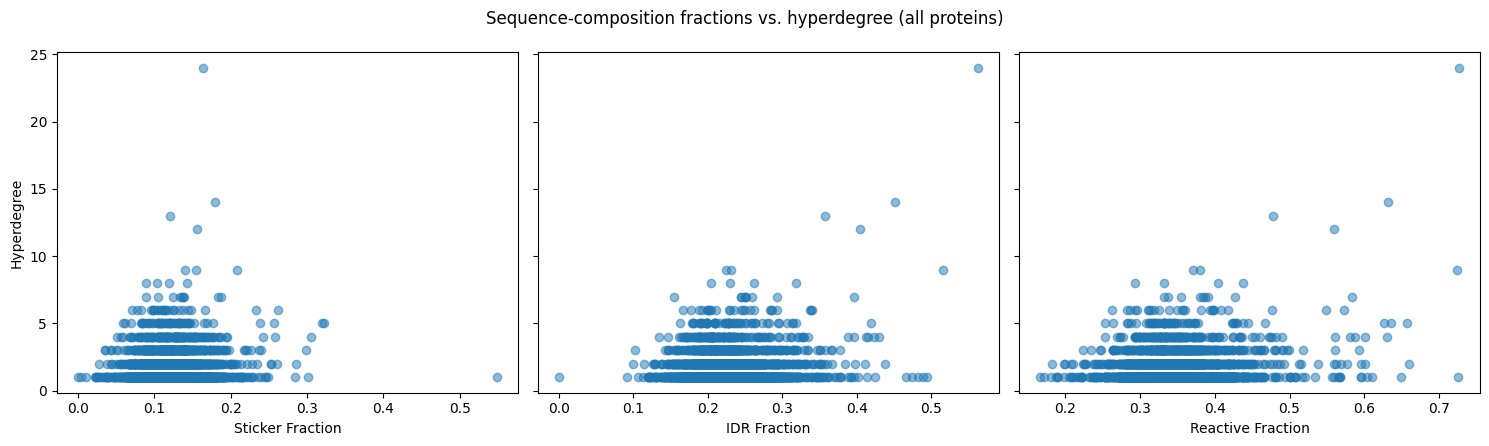

In [60]:
fig, axes = plt.subplots(1, len(SEQ_FEATURES), figsize=(15, 4.5), sharey=True)
for ax, feature in zip(axes, SEQ_FEATURES):
    ax.scatter(frame_all[feature], frame_all["Hyperdegree"], alpha=0.5)
    ax.set_xlabel(feature)
axes[0].set_ylabel("Hyperdegree")
fig.suptitle("Sequence-composition fractions vs. hyperdegree (all proteins)")
plt.tight_layout()
plt.show()

## Validation: IUPred length vs. sequence length

Each protein's IUPred score vector should have one value per residue.

In [61]:
def lengths_match(score_list, seq):
    return isinstance(seq, str) and len(score_list) == len(seq)


matches = [lengths_match(s, q) for s, q in zip(protein_table["iupred_score"], protein_table["sequence"])]
n_bad = len(matches) - sum(matches)
print(f"Proteins with matching IUPred and sequence length: {sum(matches)} of {len(matches)}")
if n_bad:
    print(f"Mismatches (or missing sequence): {n_bad}")
    print(protein_table.loc[[not m for m in matches], "uniprot_id"].head(10).tolist())

Proteins with matching IUPred and sequence length: 4352 of 4352
